In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd



Running system command with arguments
   gfortran PK_force.f90 PK_force_c_wrapper.f90 -fPIC -shared -O3 -o PK_force.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored




Running system command with arguments
   gfortran mod_gbdd.f90 mod_gbdd_c_wrapper.f90 -fPIC -shared -O3 -o mod_gbdd.arm64.so


ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored
ld: warning: duplicate -rpath '/opt/miniconda3/envs/pylabdd/lib' ignored


Simulation with N_gbn=25, delta=0.004, dtmax=5e-06
 Conducting simulation w/o PU dislocations, as tau0=0
 Starting iteration for T, tau0, D2, Lgb, Ngbn   600.00000000000000        0.0000000000000000        1.0000000000000000       0.10000000000000001               25
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     2000000   4.9999999999999979E-006   9.8697030044167716E-006   4.4173558482196051E-007   2.4201155101931021E-004           0           1  -1.7976931348623157E+308
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     4000000   4.9999999999999979E-006   1.9869703005412990E-005   3.2697416480546400E-007   1.7949726749295235E-004           0           1  -1.7976931348623157E+308
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     6000000   4.9999999999999979E-006   2.9869703008587126E-005   2.4250857786980849E-007   1.3312865620768524E-004           0           1  -1.7976931348623157E+308
 Iteration, dt, ttot(s), max(bdot

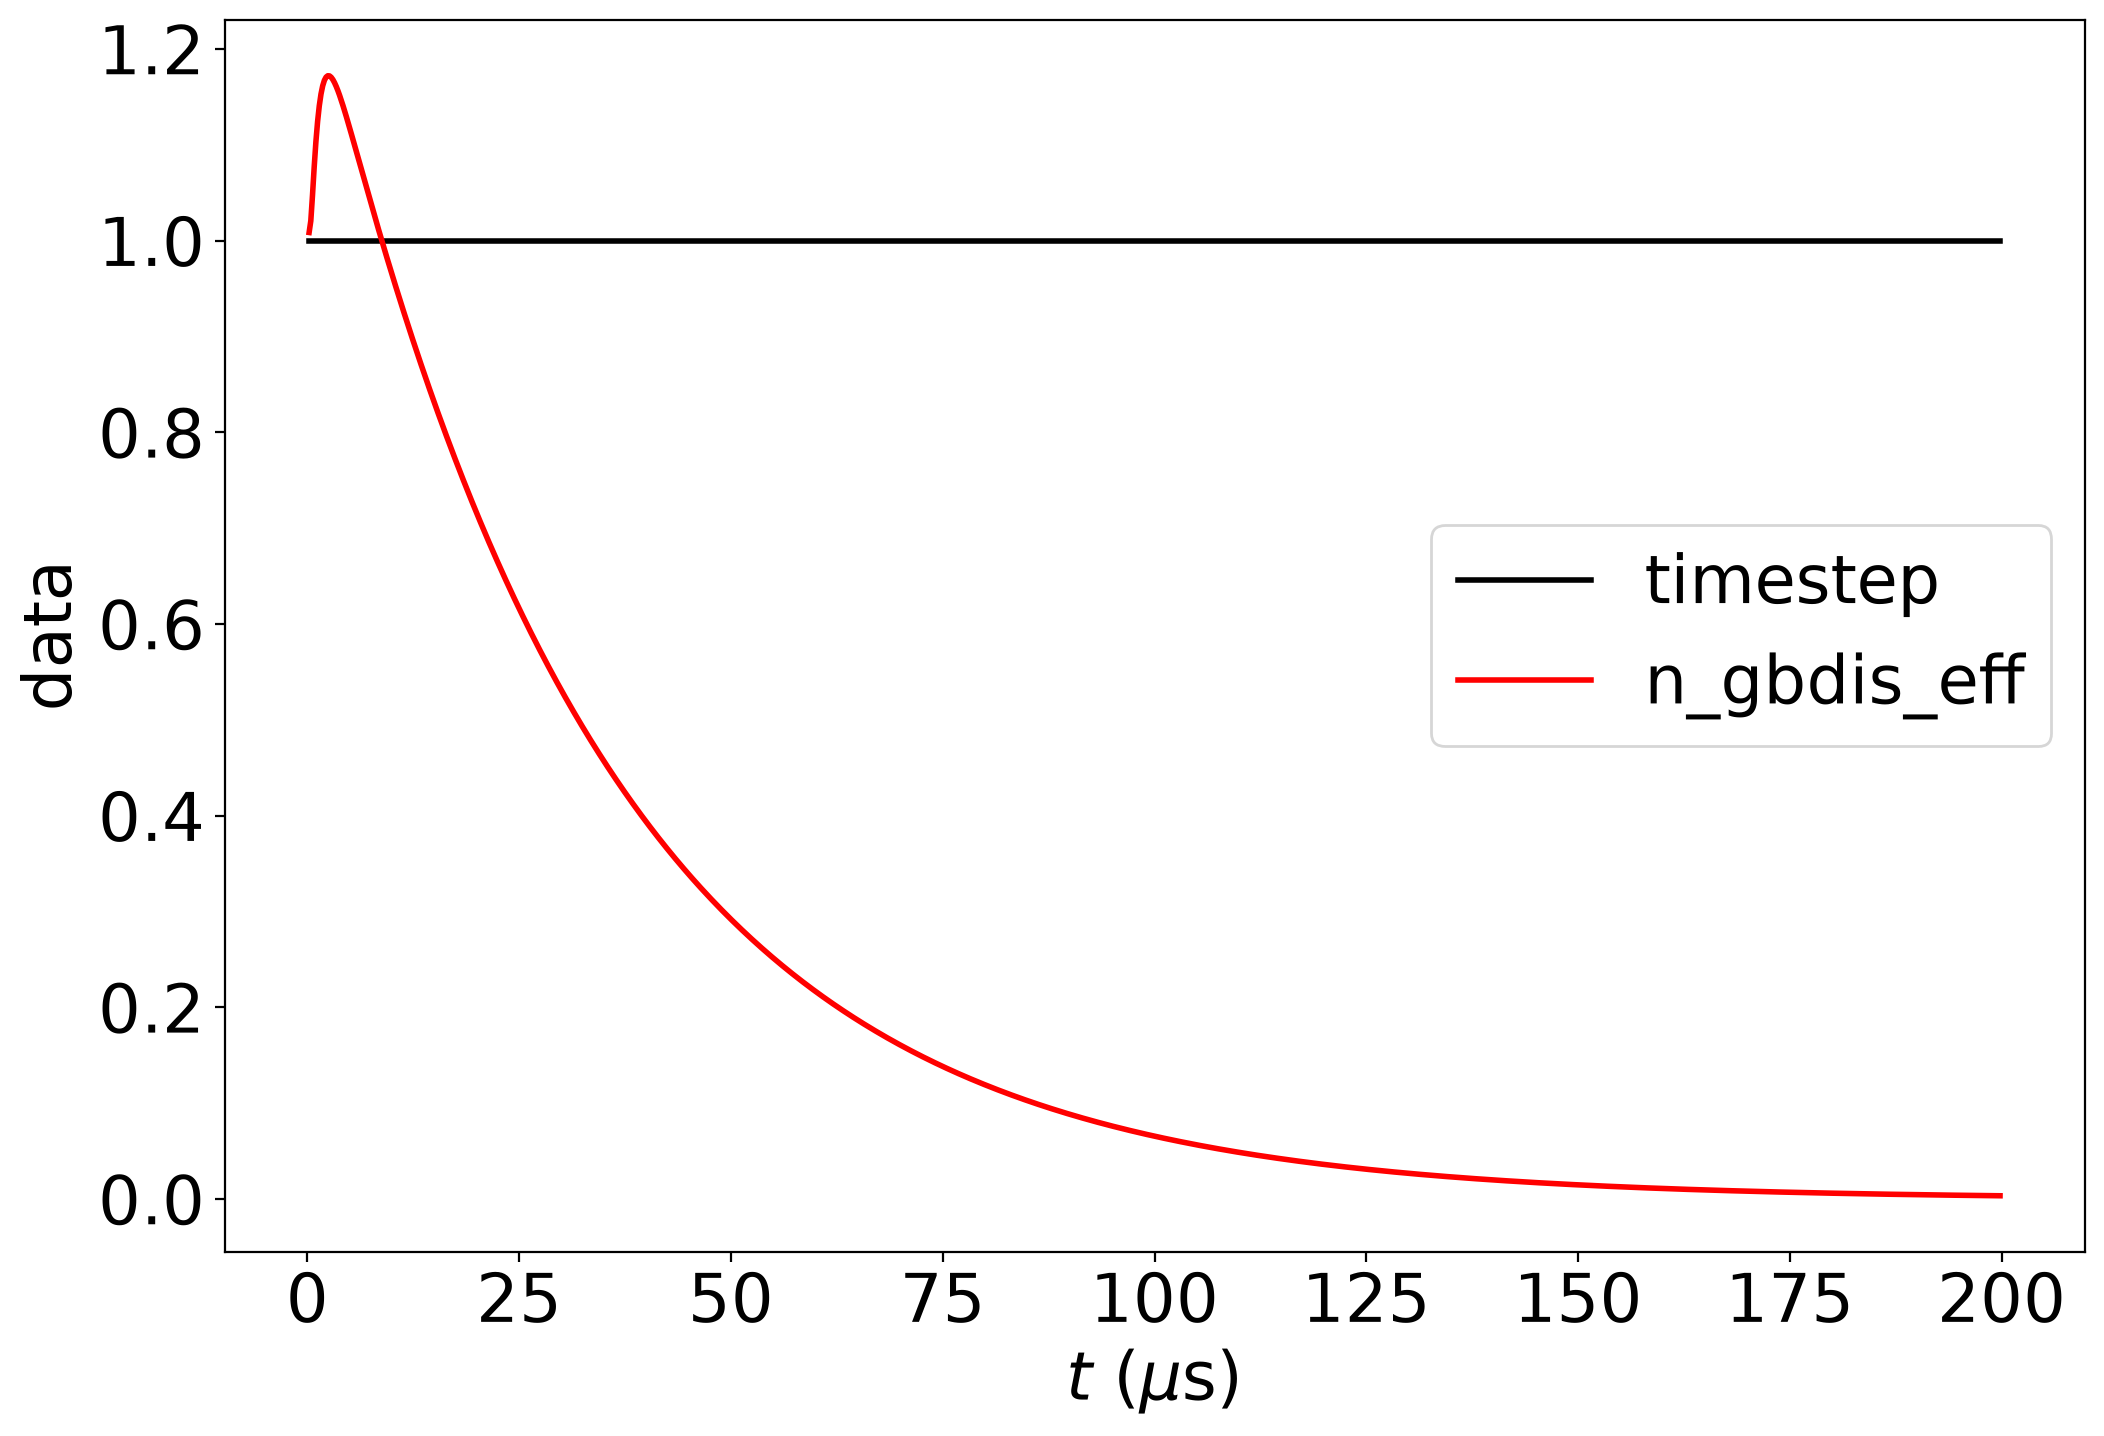

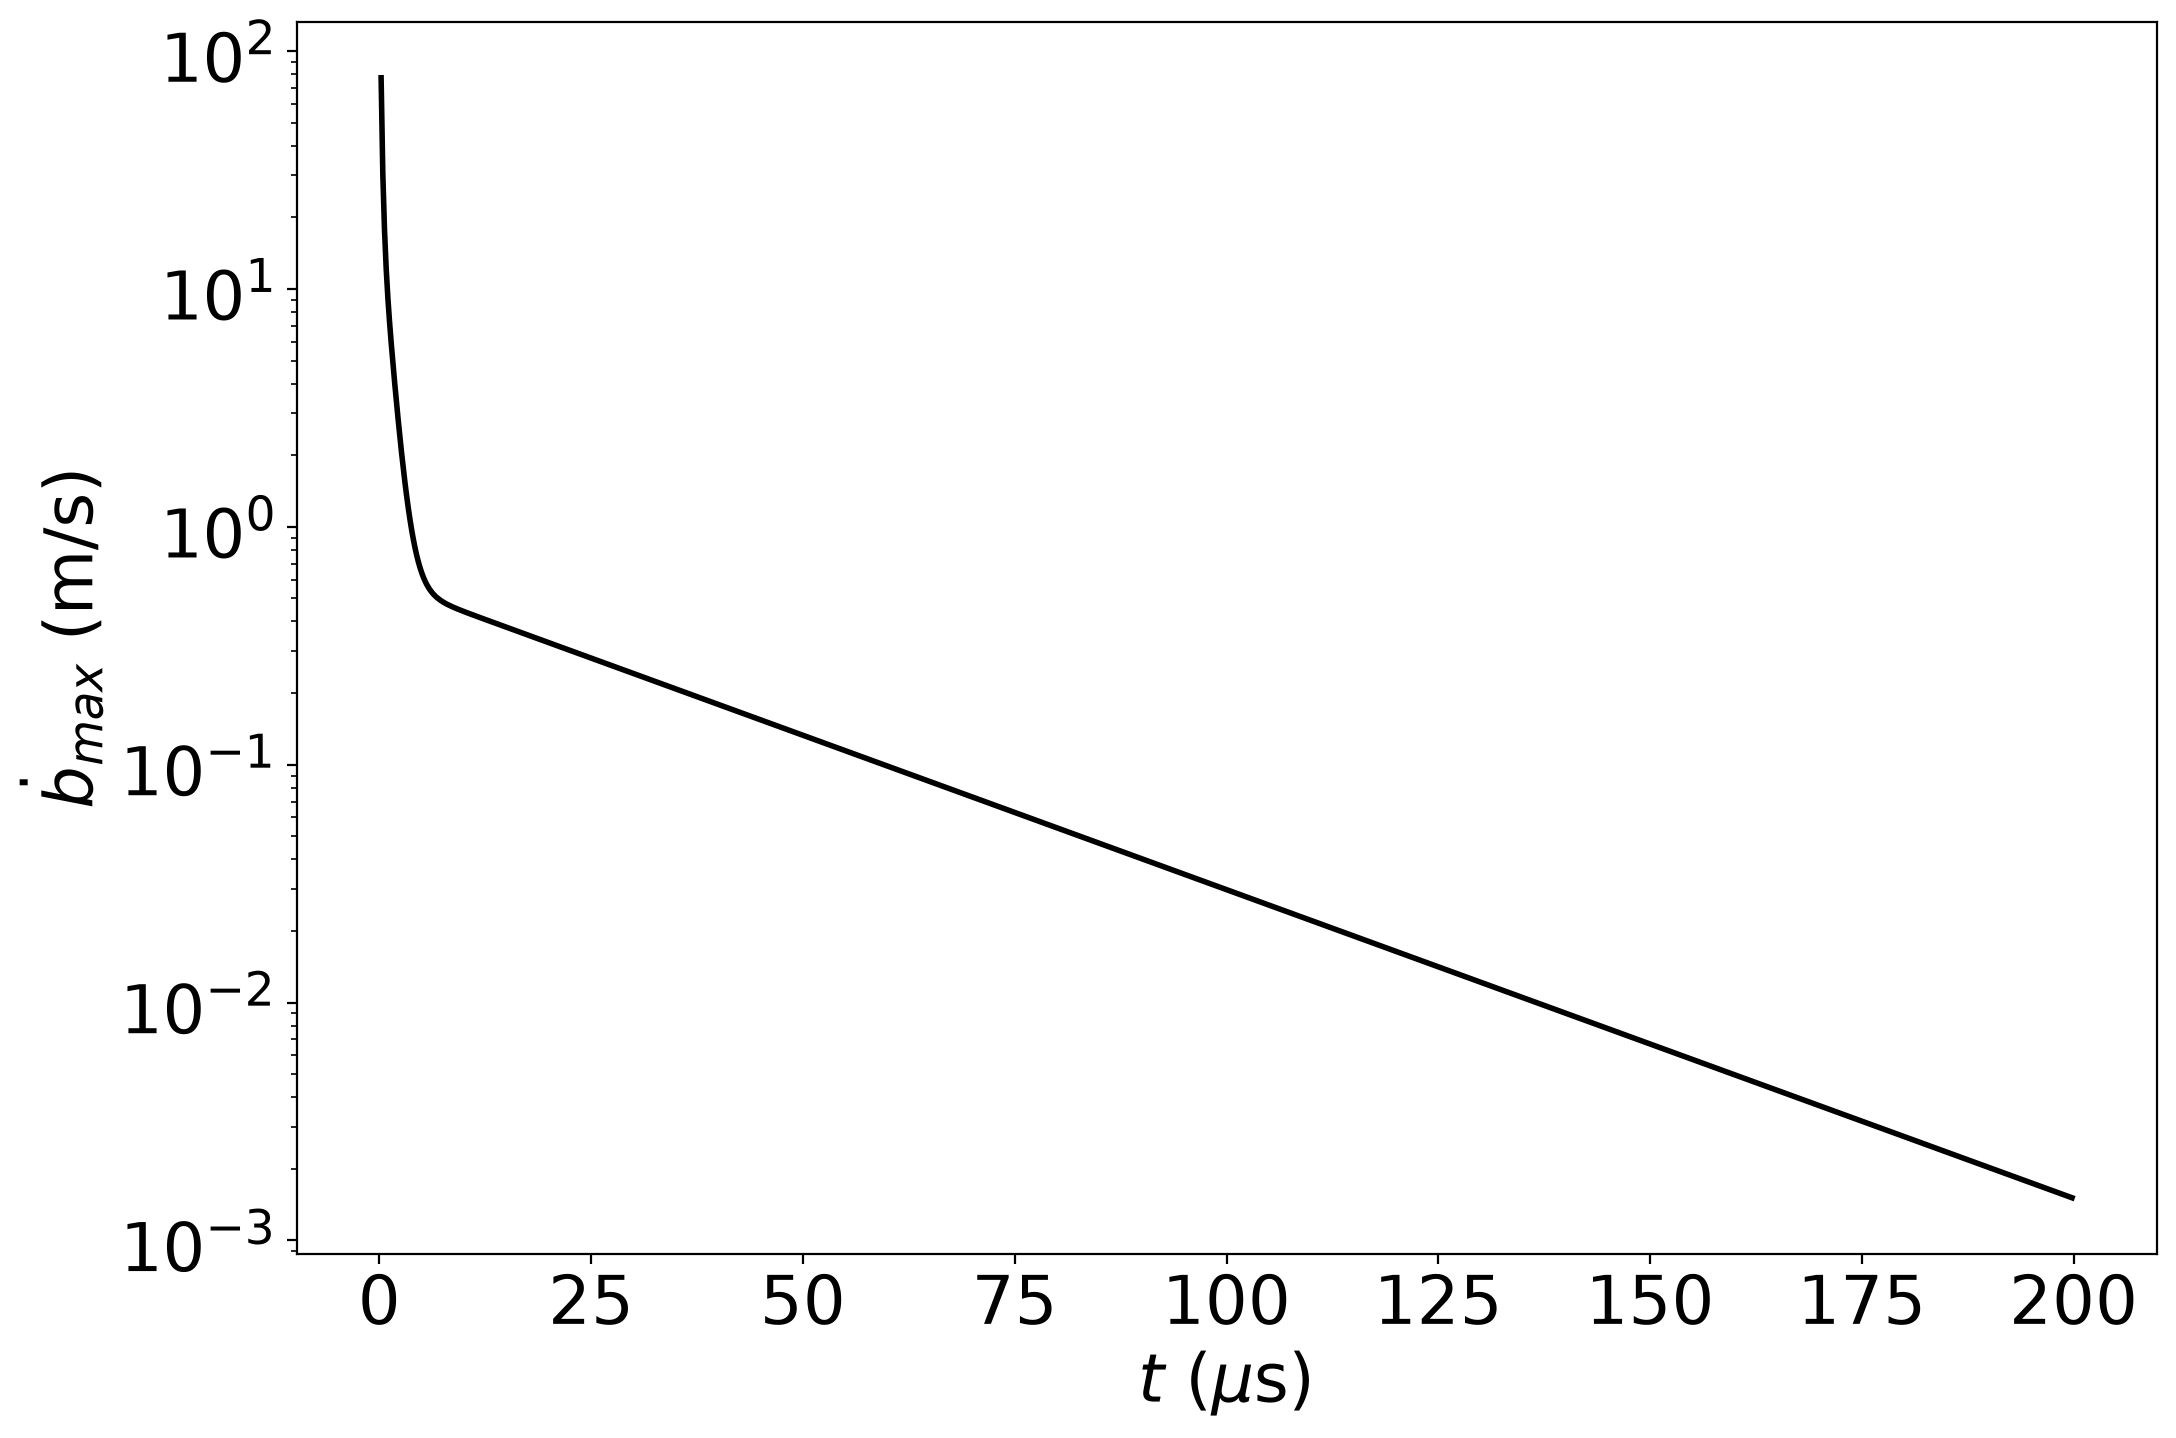

In [2]:
#define system parameters
maxout = 1000
temp = 600.0
tau0 = 0.0
lgb = 0.1
grain_size = 1.0
tfin = 200.
niter = 200_000_000
delta = 0.004
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 5.e-6  # 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
print(f"Simulation with N_gbn={ngbn}, delta={delta}, dtmax={dtmax}")
gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=grain_size,
                   tfin=tfin, niter=niter, maxout=maxout,
                   dtmax=dtmax,
                   screenout=True)
gbdd.run_sim()
gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
gbdd.plot_time_series('max_bdot')

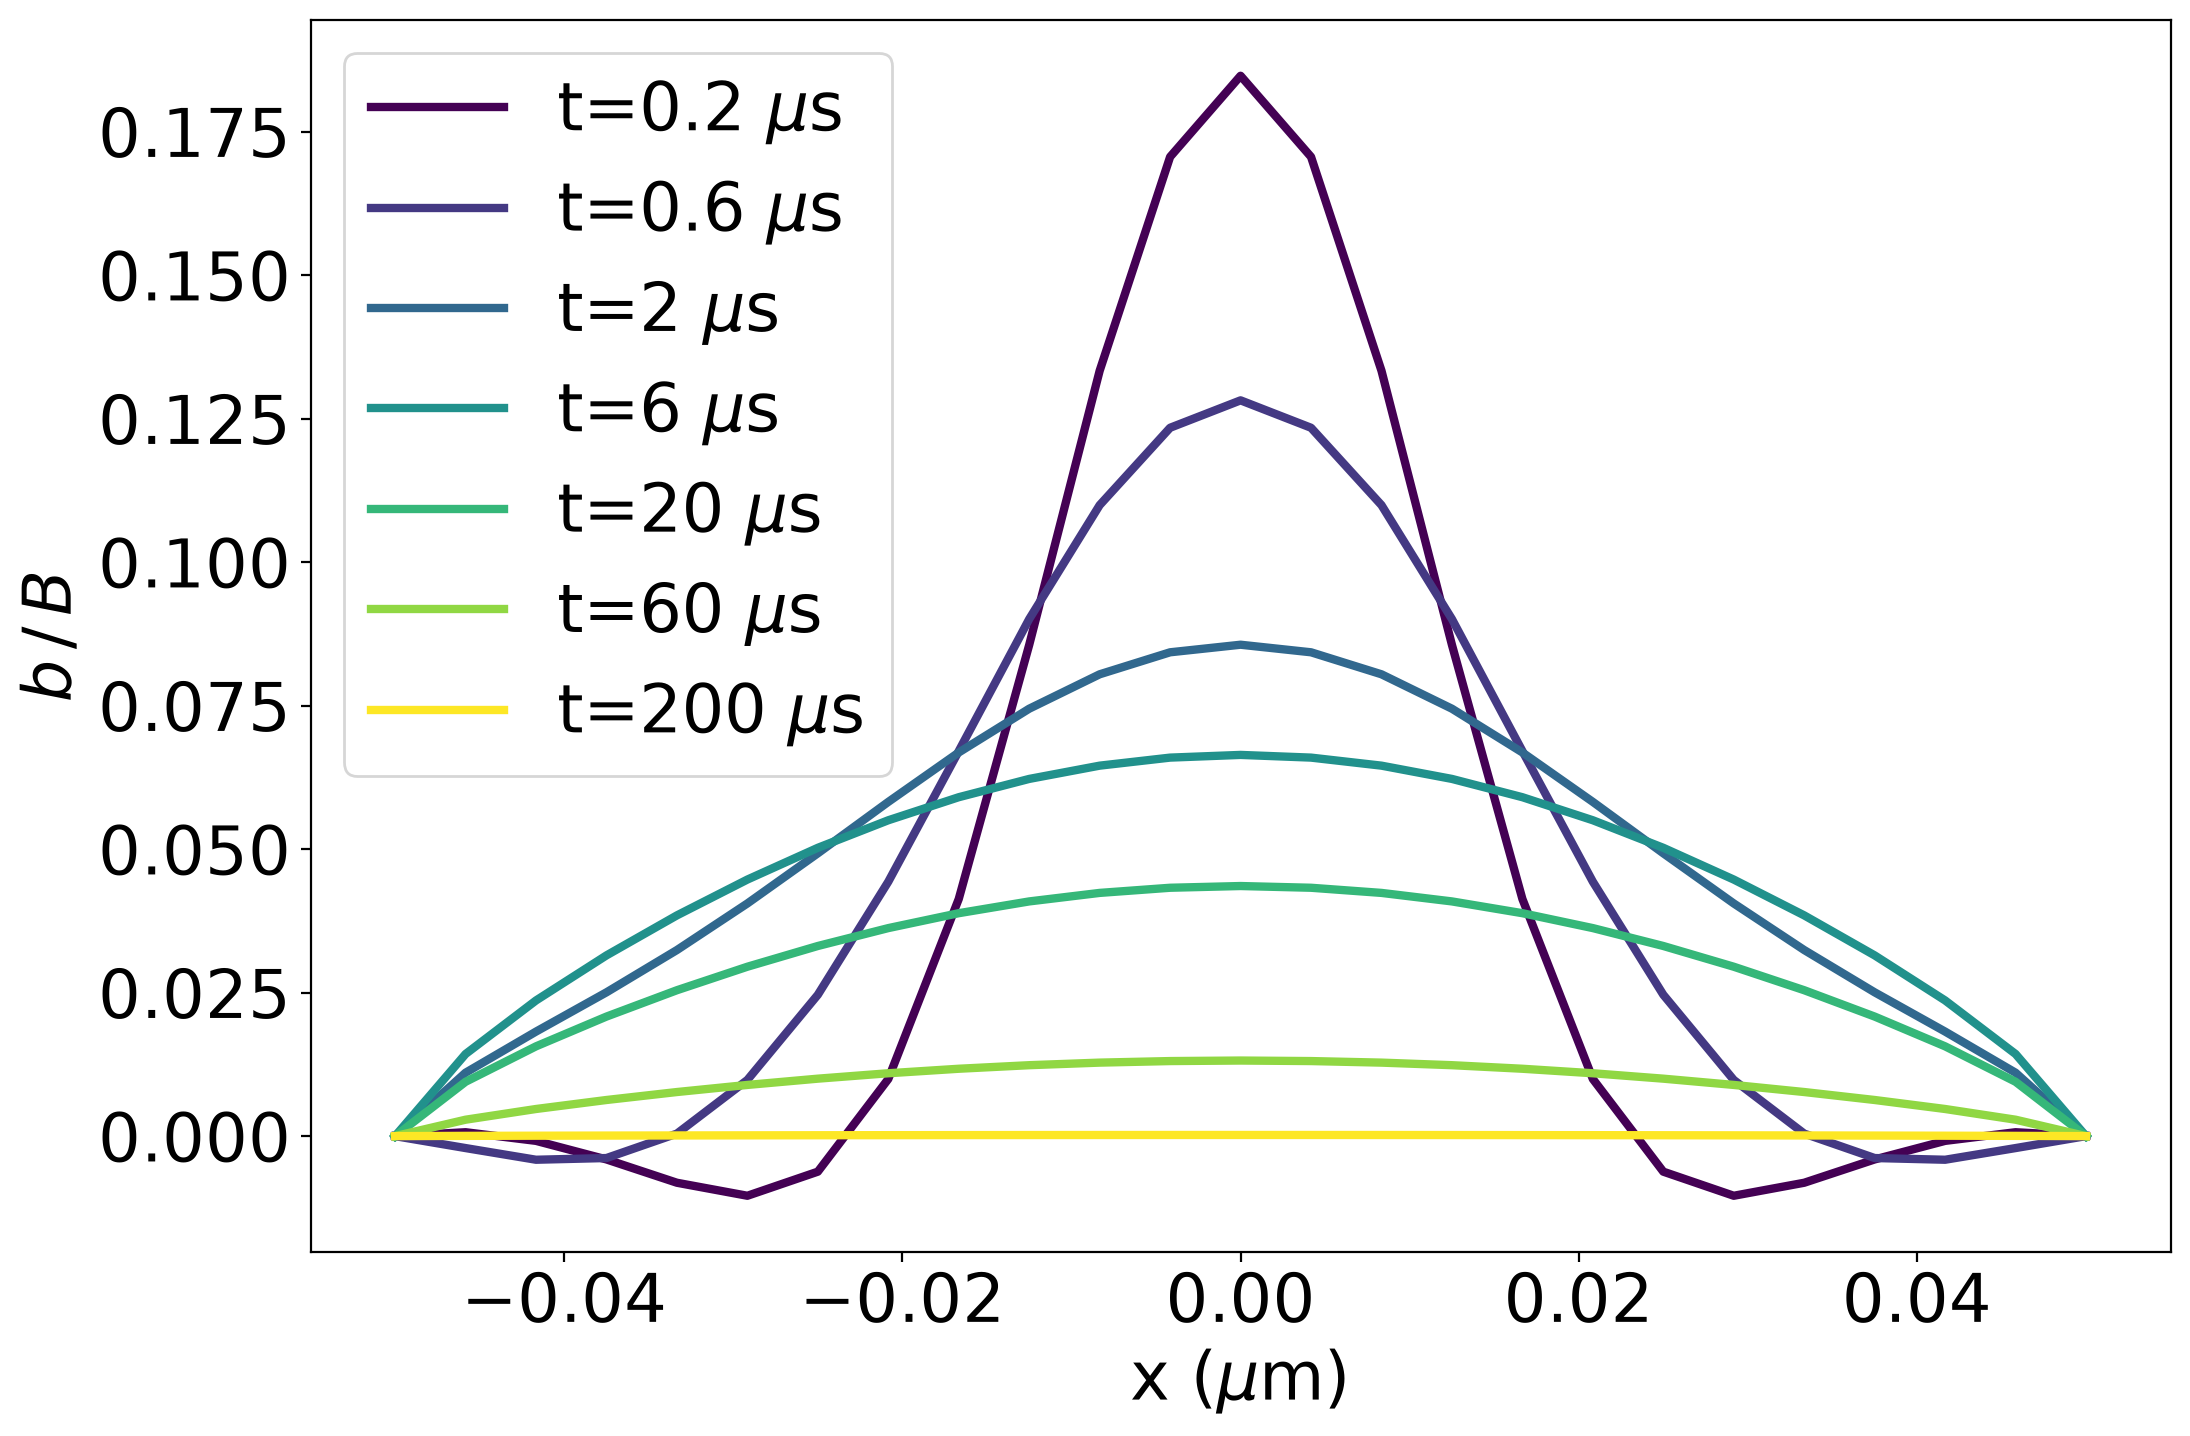

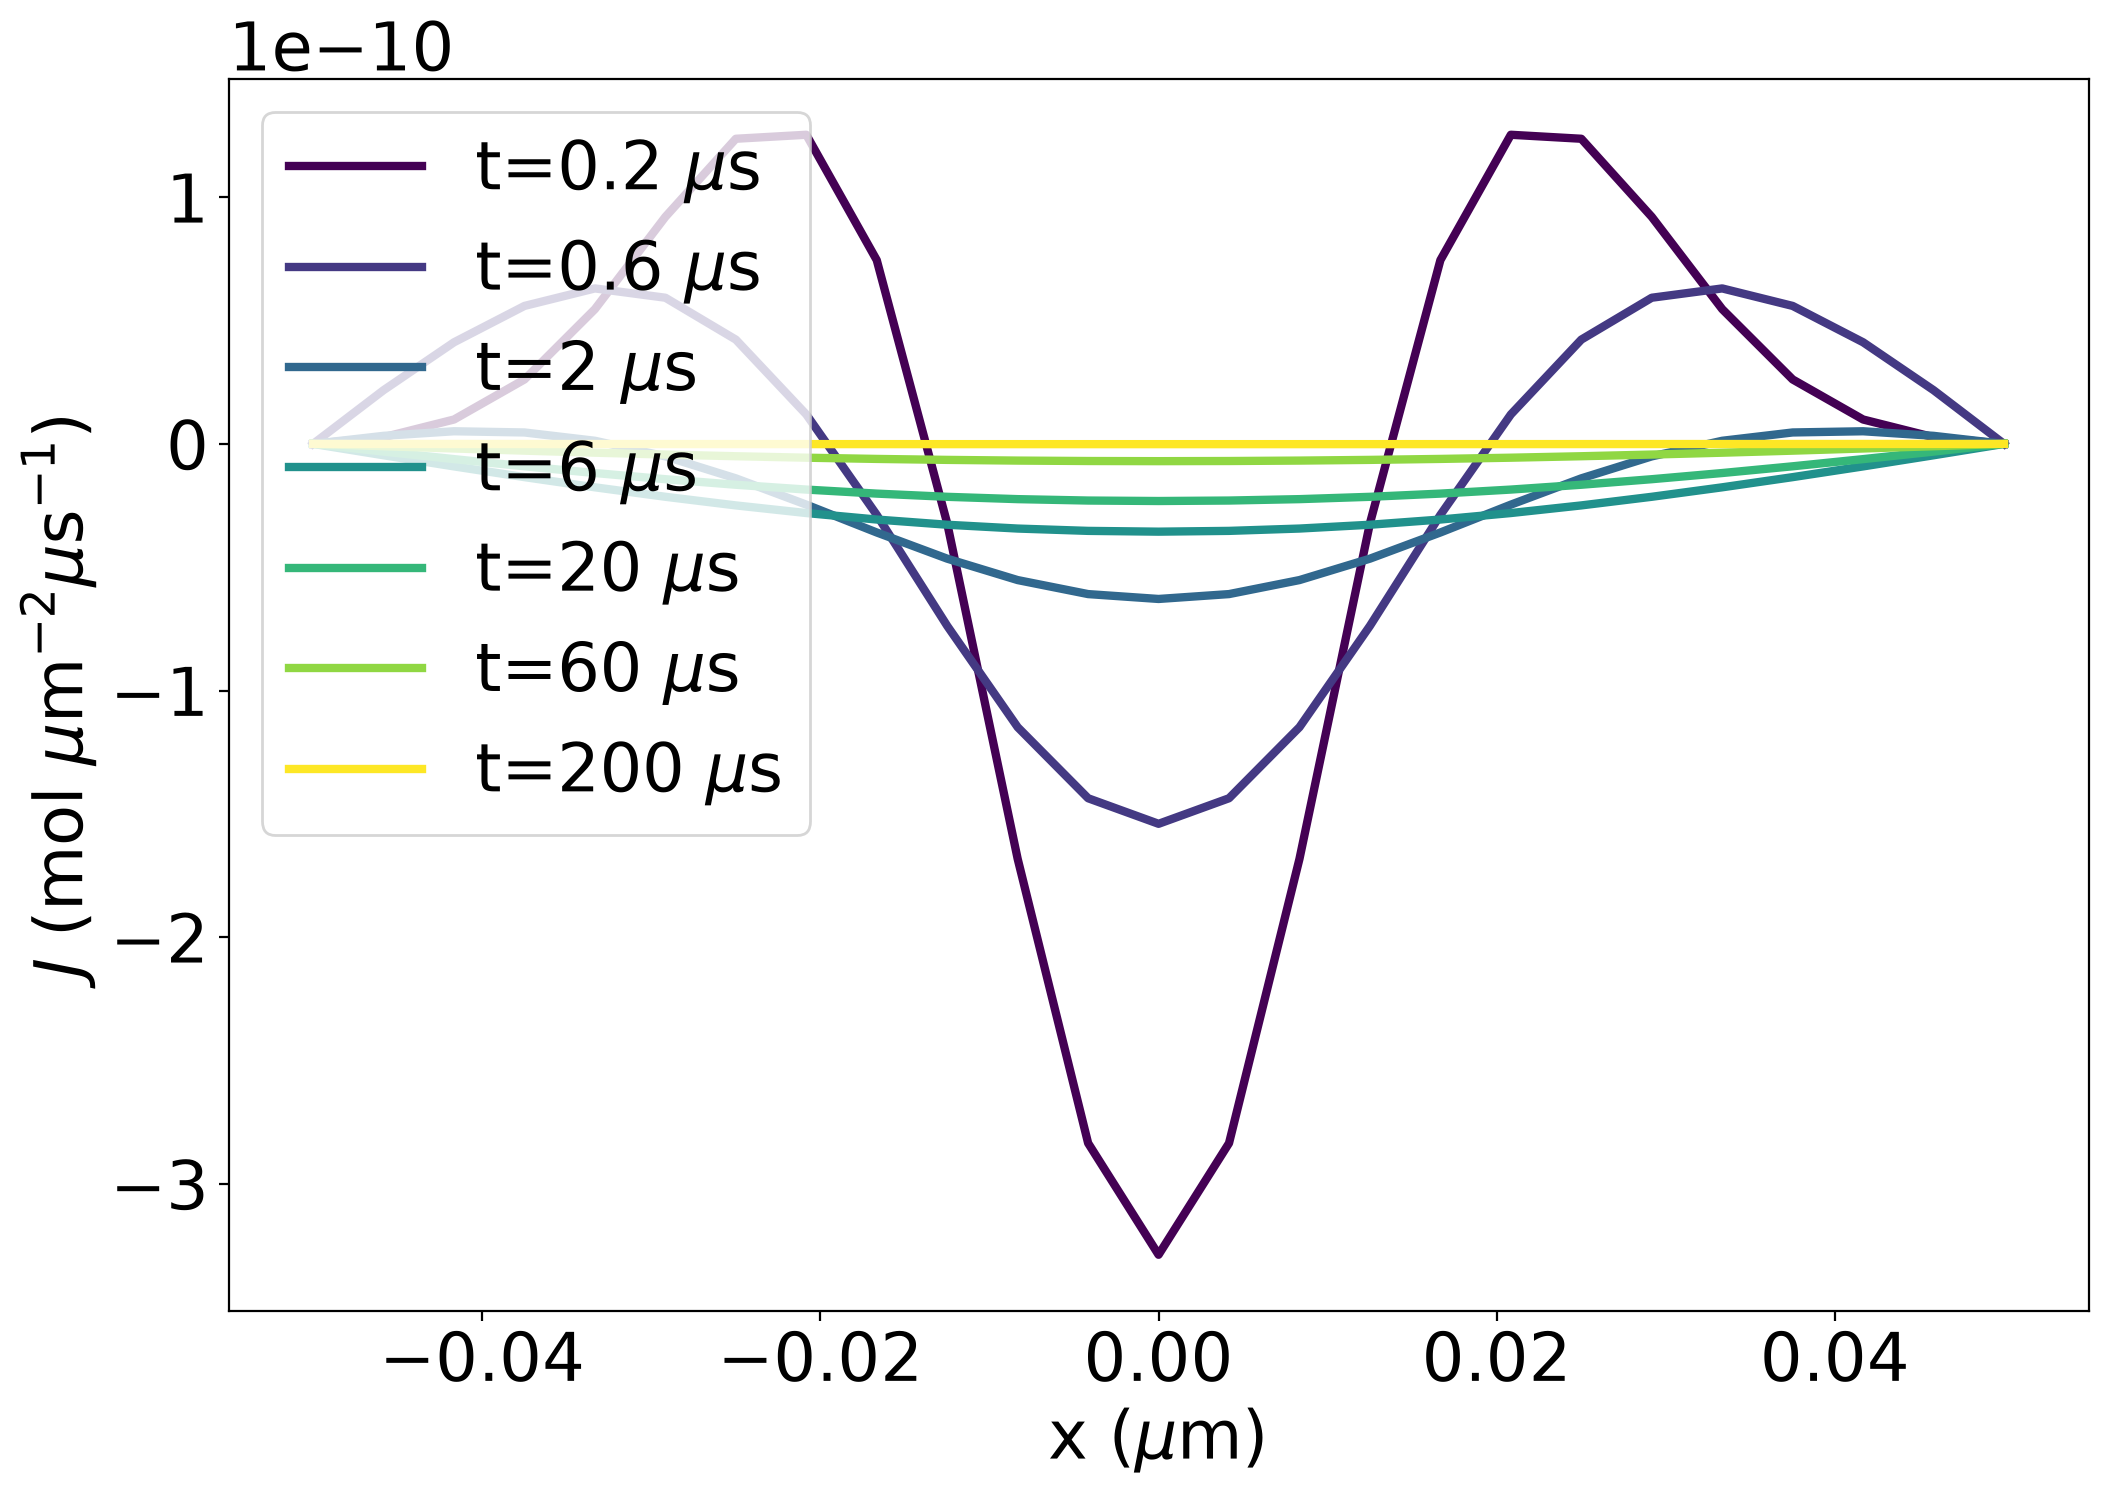

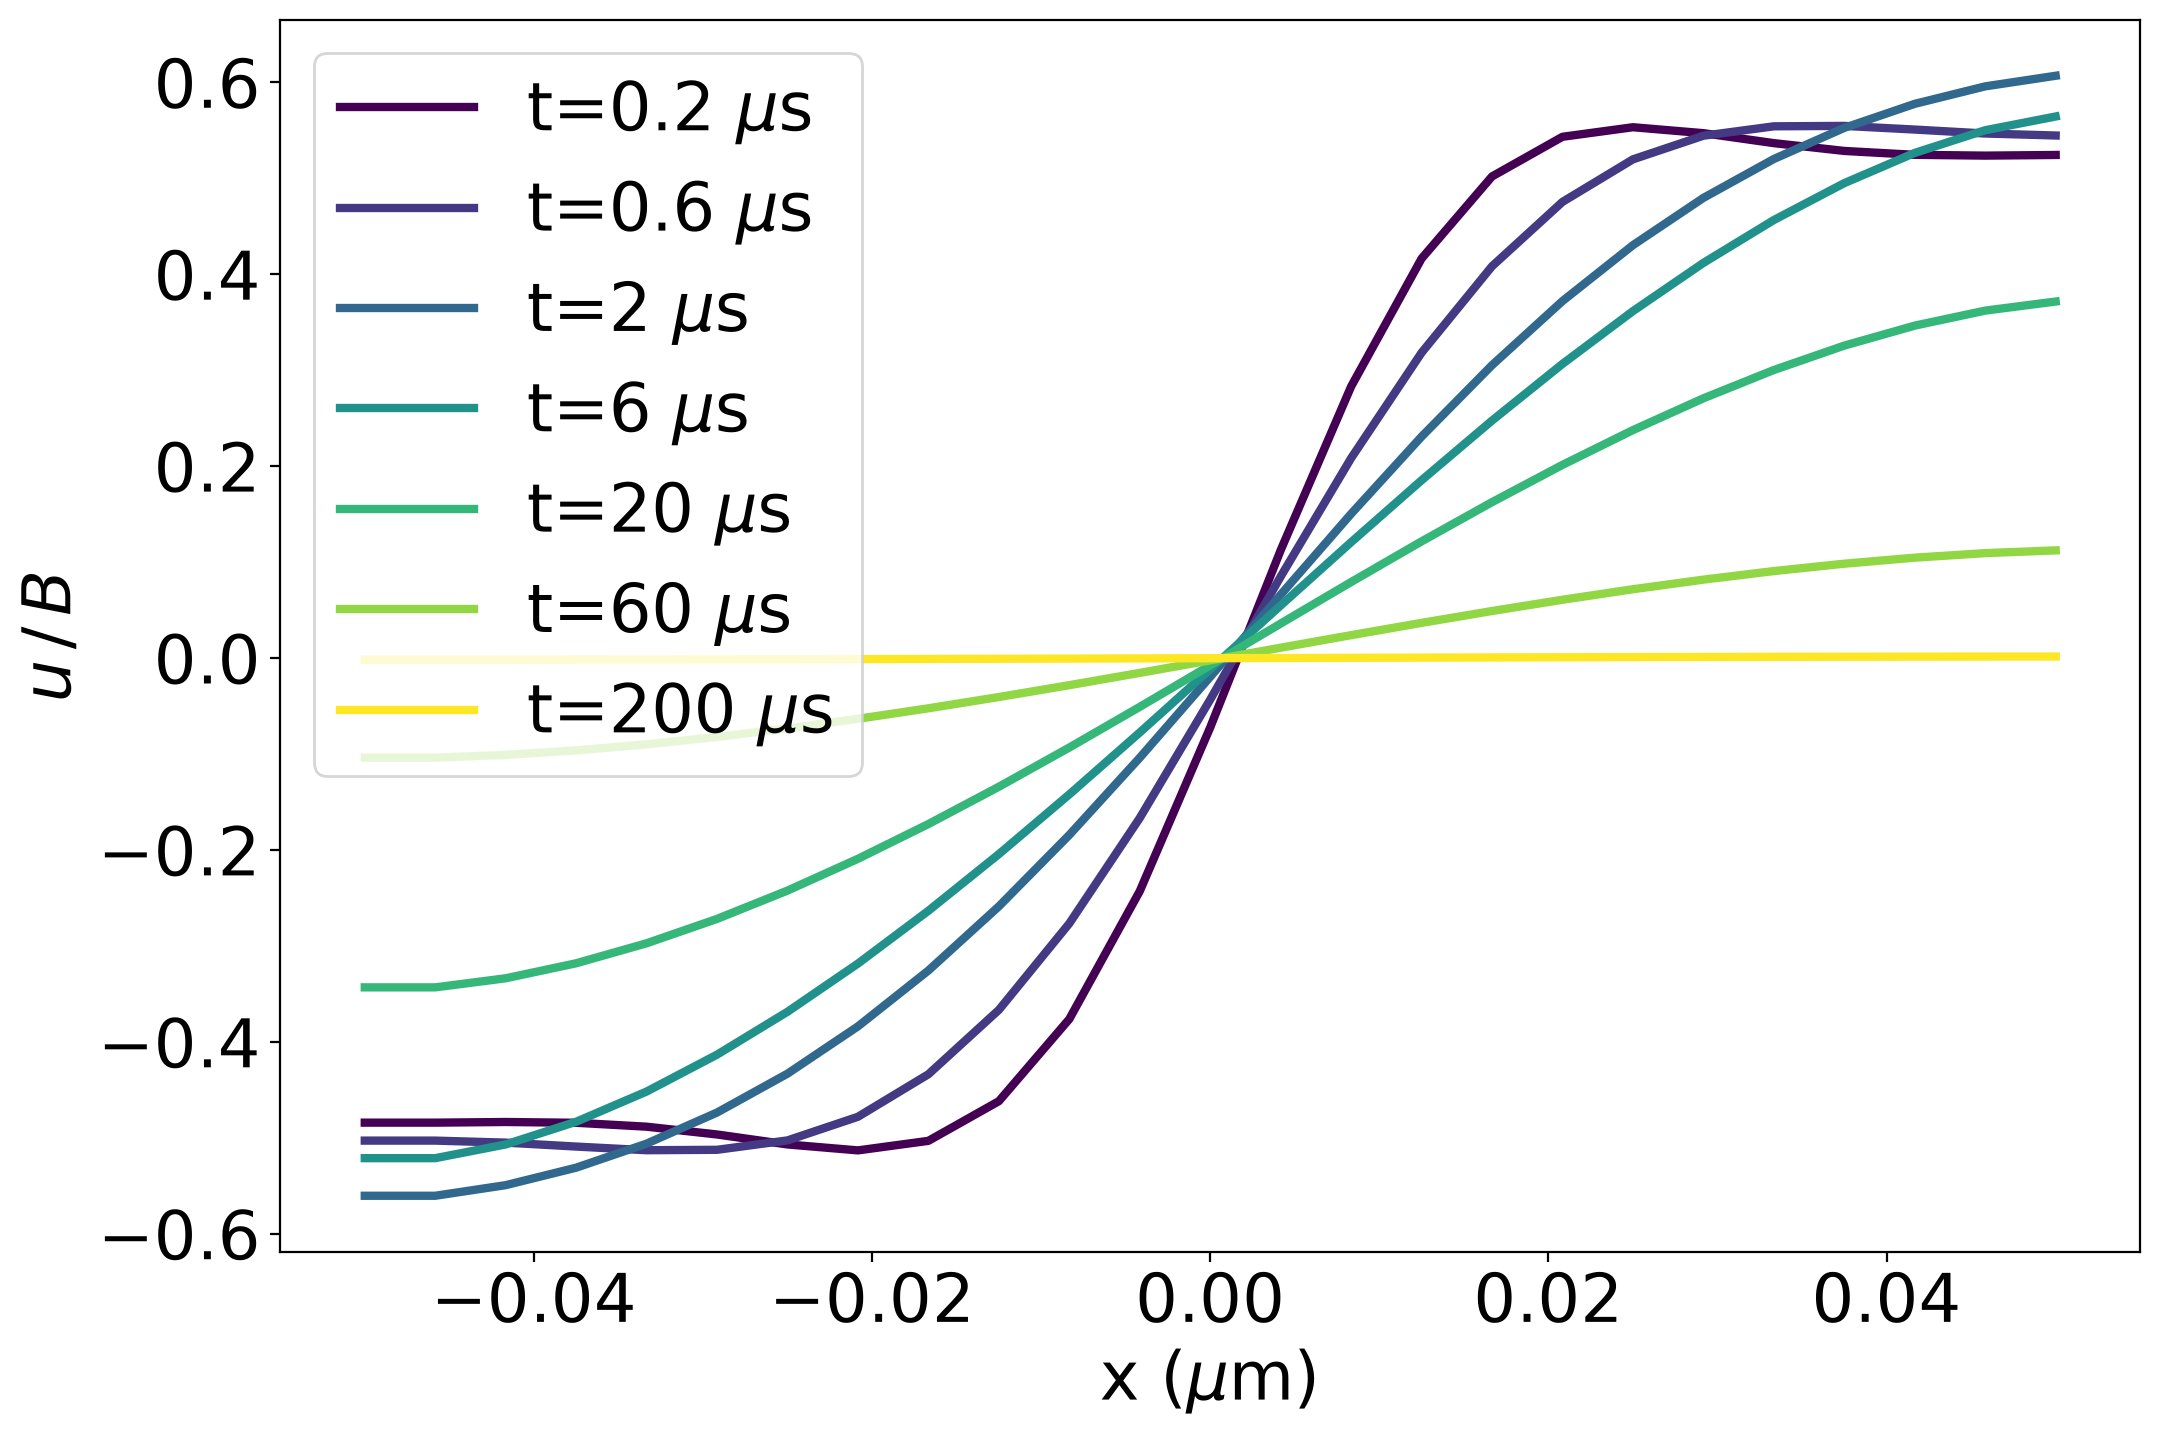

In [13]:
t_ = [.2, 0.6, 2, 6, 20., 60, 200.]
gbdd.plot_field('bfield', 
                times=t_,
                lw=3,
                file='F4a_bfield_gb01_t600.pdf')
gbdd.plot_field('flux', 
                times=t_,
                lw=3,
                file='F4b_flux_gb01_t600.pdf')
gbdd.plot_field('displacement', 
                times=t_,
                lw=3,
                file='F4c_displacement_gb01_t600.pdf')

In [5]:
print(gbdd.nout)
print(gbdd.sim_time[:10])
print(gbdd.sim_time[gbdd.nout-10:])

999
[0.       0.200203 0.400408 0.600613 0.800818 1.001023 1.201228 1.401433
 1.601638 1.801843]
[198.00274286 198.20294786 198.40315286 198.60335786 198.80356286
 199.00376786 199.20397286 199.40417786 199.60438286 199.80458786]
